# 05 Evaluation

In 04a and 04b, two races chose a winner each: **OLS** to predict consumption and **Logit** to predict if poor/not poor.
They both use the same 53 columns (Set A, without the village-level columns).

In [3]:
import sys
sys.path.append("..")   # the notebook finds the shared code in src/, one folder up

import os
import warnings
warnings.filterwarnings("ignore", message=".*penalty.*")        # hide a warning, because scikit-learn will rename "penalty", but results are the same

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import PredefinedSplit

from src.utils import SEED, load_data, select_by_quota, recall_at_quota, within_village_auc
from src.features import SET_A, without_village_level, make_preprocessor

train, test = load_data()   # test is not used before the very end of part 5
cv = PredefinedSplit(train["fold"])   # the same 5 village folds as in 03, 04a and 04b
os.makedirs("../outputs/figures", exist_ok=True)
print("train:", train.shape, "| villages:", train["hhea"].nunique(), "| SEED:", SEED)

train: (4090, 113) | villages: 512 | SEED: 40


## 1. Summarises all results for both races 04a and 04b, from set A and set B

Mean CV recall at the quota and within-village AUC, numbers come from outputs of the 4 notebooks.

| Race | Model | Set A | Set B |
|---|---|---|---|
| Regression (04a) | **OLS (winner)** | **56.1% (3.0)**, AUC 0.824 | **56.5% (2.8)**, AUC 0.828 |
| | Ridge | 56.1% | 57.0% |
| | Lasso | 56.2%, AUC 0.825 | 57.1%, AUC 0.834 |
| | Elastic Net | 56.2% | 56.9% |
| | Boosting | 56.1%, AUC 0.823 | 56.8%, AUC 0.830 |
| Classification (04b) | **Logit (winner)** | **56.2% (3.2)**, AUC 0.814 | **56.5% (4.0)**, AUC 0.825 |
| | Logit L2 | 56.0% | 56.5% |
| | Logit L1 | 56.0% | 56.9%, AUC 0.828 |
| | Boosting | 55.9%, AUC 0.824 | 55.4% |
| | Neural net | 55.8% | 56.6% |
| References (03) | Government formula | 54.0% (2.4), AUC 0.777 | |
| | Random | 36.4% | |
| | Perfect ranking | 68.6%, AUC 1.000 | |

- In both regression and classification and with both sets A and B, the models are tied with the best because their differences are smaller than the normal variation from luck. Therefore, the simplest model wins: OLS and Logit.
- Set B (+ 39 items) adds at most approximately one point, which is smaller than the spread across folds. The main comparison thus stays with set A.

## 2. The two winners (OLS and Logit) side by side (cross-validation)

We fit the two winners again, fold by fold on the same villages, and also the two boosting models with the settings already chosen in 04a and 04b.


In [4]:
# Linear models (OLS, Logit): set A without the village-level columns, as in 04a and 04b
features = without_village_level(SET_A)     # 53 columns
X_train = train[features].astype(float)     # <NA> becomes NaN, filled in the pipeline

# Boosting: all of set A (with district, urban and village facilities), as in 04a and 04b
features_full = SET_A       # 66 columns
X_train_full = train[features_full].copy()
num_cols = [c for c in features_full if c != "kabu"]        # all columns except the district code
X_train_full[num_cols] = X_train_full[num_cols].astype(float)

# The two targets: the pairs differ only here
y_consumption = train["LOGCONSUMPTION"]     # regression: log consumption per person
y_poor = train["poor"].astype(int)          # classification: 1 = poor, 0 = not poor
print("features:", len(features), "| with village-level columns:", len(features_full))

features: 53 | with village-level columns: 66


In [5]:
# Settings chosen by the searches in 04a and 04b (set A), copied here so the models are identical
best_params_boost_reg = {"model__min_samples_leaf": 50, "model__max_iter": 200, "model__max_depth": 2,
                         "model__learning_rate": 0.1, "model__l2_regularization": 1}        # 04a
best_params_boost_clf = {"model__min_samples_leaf": 100, "model__max_iter": 800, "model__max_depth": 2,
                         "model__learning_rate": 0.05, "model__l2_regularization": 0.1}     # 04b

def make_models():      # produces 4 new models, so that each fold starts from the beggining and cannot learn from the past
    """The four models with their data (new, unfitted copies every time it is called)."""
    ols = Pipeline([("prep", make_preprocessor(features, drop_first=True)),
                    ("model", LinearRegression())])
    logit = Pipeline([("prep", make_preprocessor(features, drop_first=True)),
                      ("model", LogisticRegression(penalty=None, max_iter=5000))])
    boost_reg = Pipeline([("prep", make_preprocessor(features_full, scale=False)),
                          ("model", HistGradientBoostingRegressor(early_stopping=False, random_state=SEED))])
    boost_reg.set_params(**best_params_boost_reg)
    boost_clf = Pipeline([("prep", make_preprocessor(features_full, scale=False)),
                          ("model", HistGradientBoostingClassifier(early_stopping=False, random_state=SEED))])
    boost_clf.set_params(**best_params_boost_clf)

    # higher_is_poorer: False = low predicted consumption is poor, True = high probability of being poor is poor
    return {
        "OLS":                    {"model": ols,       "X": X_train,      "y": y_consumption, "higher_is_poorer": False},
        "Logit":                  {"model": logit,     "X": X_train,      "y": y_poor,        "higher_is_poorer": True},
        "Boosting (consumption)": {"model": boost_reg, "X": X_train_full, "y": y_consumption, "higher_is_poorer": False},
        "Boosting (poverty)":     {"model": boost_clf, "X": X_train_full, "y": y_poor,        "higher_is_poorer": True},
    }

In [6]:
rng = np.random.default_rng(SEED)       # fixed seed, so the random baseline is the same every time
rows = []       # one row per model and fold

for k, (train_idx, val_idx) in enumerate(cv.split()):       # k = fold number (0 to 4)
    val = train.iloc[val_idx].copy()        # validation villages of fold k

    # 1. The four models: learn on the other 4 folds, predict fold k
    for name, m in make_models().items():
        m["model"].fit(m["X"].iloc[train_idx], m["y"].iloc[train_idx])
        if m["higher_is_poorer"]:
            val[name] = m["model"].predict_proba(m["X"].iloc[val_idx])[:, 1]        # probability of being poor
        else:
            val[name] = m["model"].predict(m["X"].iloc[val_idx])        # predicted log consumption
        selected = select_by_quota(val, name, higher_is_poorer=m["higher_is_poorer"])
        rows.append({"model": name, "fold": k, "recall": recall_at_quota(val, selected),        # within poor, who received a transfer
                     "within_auc": within_village_auc(val, name, higher_is_poorer=m["higher_is_poorer"])})      # in the same village, how well the model classifies poor as non-poor

    # 2. References (same as in 03): government formula and perfect ranking
    for name, score in [("Government formula", "pcexppred"), ("Perfect ranking", "LOGCONSUMPTION")]:        # official score of the gvmnt
        selected = select_by_quota(val, score, higher_is_poorer=False)      # low consumption = poor
        rows.append({"model": name, "fold": k, "recall": recall_at_quota(val, selected),
                     "within_auc": within_village_auc(val, score, higher_is_poorer=False)})

    # 3. Random selection: 100 draws, because one draw alone depends on luck
    random_recalls = []
    for i in range(100):
        val["random_score"] = rng.random(len(val))
        random_recalls.append(recall_at_quota(val, select_by_quota(val, "random_score", higher_is_poorer=True)))
    rows.append({"model": "Random", "fold": k, "recall": np.mean(random_recalls), "within_auc": 0.5})
    # why 0.5: a random ranking orders a poor/non-poor pair correctly half of the time

cv_results = pd.DataFrame(rows)     # transforms the list  in table 
by_fold = cv_results.pivot(index="fold", columns="model", values="recall")      # recall: one row per fold
display(by_fold.round(3))

model,Boosting (consumption),Boosting (poverty),Government formula,Logit,OLS,Perfect ranking,Random
fold,,,,,,,
0,0.582,0.579,0.559,0.589,0.589,0.716,0.370
1,0.582,0.597,0.544,0.582,0.582,0.682,0.374
2,0.548,0.525,0.548,0.538,0.545,0.664,0.353
3,0.583,0.583,0.552,0.583,0.573,0.729,0.382
4,0.509,0.513,0.498,0.516,0.516,0.639,0.341


In [7]:
# Mean and standard deviation across the 5 folds, best recall first
summary = cv_results.groupby("model")[["recall", "within_auc"]].agg(["mean", "std"])
summary = summary.sort_values(("recall", "mean"), ascending=False)

# Share of the possible improvement: random = 0%, perfect ranking = 100%
r_random = summary[("recall", "mean")]["Random"]
r_perfect = summary[("recall", "mean")]["Perfect ranking"]
summary[("share of possible gain", "")] = (summary[("recall", "mean")] - r_random) / (r_perfect - r_random)
display(summary.round(3))

recall        within_auc        share of possible gain
                         mean    std       mean    std                       
model                                                                        
Perfect ranking         0.686  0.037      1.000  0.000                  1.000
Logit                   0.562  0.032      0.814  0.027                  0.613
OLS                     0.561  0.030      0.824  0.025                  0.611
Boosting (consumption)  0.561  0.033      0.823  0.022                  0.611
Boosting (poverty)      0.559  0.038      0.824  0.026                  0.606
Government formula      0.540  0.024      0.777  0.023                  0.547
Random                  0.364  0.017      0.500  0.000                  0.000

## 3. Comparison predicting consumption with predicting poverty directly

In [8]:
# Paired comparison: the same villages are in every fold, so we compare fold by fold
pairs = {
    "OLS - Logit (linear pair)":       ("OLS", "Logit"),
    "Boosting: consumption - poverty": ("Boosting (consumption)", "Boosting (poverty)"),
    "OLS - Government formula":        ("OLS", "Government formula"),
    "Logit - Government formula":      ("Logit", "Government formula"),
}

rows = []
for pair_name, (a, b) in pairs.items():
    diff = by_fold[a] - by_fold[b]   # difference in recall in each of the 5 folds
    rows.append([pair_name, diff.mean(), diff.std(), (diff > 0).sum()])

paired = pd.DataFrame(rows, columns=["Comparison", "Mean difference", "Std across folds",
                                     "Folds above 0 (of 5)"]).set_index("Comparison")
display(paired.round(3))

,Mean difference,Std across folds,Folds above 0 (of 5)
Comparison,,,
OLS - Logit (linear pair),-0.001,0.006,1
Boosting: consumption - poverty,0.001,0.014,2
OLS - Government formula,0.021,0.016,4
Logit - Government formula,0.021,0.019,4


## 4. Draws the final figure

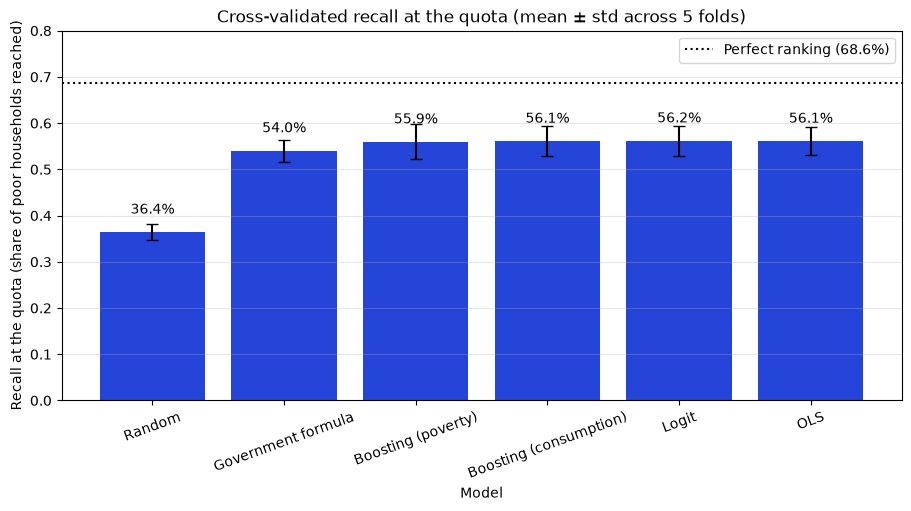

In [9]:
order = ["Random", "Government formula", "Boosting (poverty)", "Boosting (consumption)", "Logit", "OLS"]
means = summary[("recall", "mean")][order]
stds = summary[("recall", "std")][order]

fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
ax.bar(order, means, yerr=stds, capsize=4, color="#2544d8")                       # mean ± std across the 5 folds
ax.axhline(r_perfect, color="black", linestyle=":", label=f"Perfect ranking ({r_perfect:.1%})")   # the ceiling
for i, m in enumerate(means):
    ax.text(i, m + 0.04, f"{m:.1%}", ha="center")                           # value above each bar

ax.set_ylim(0, 0.8)
ax.set_xlabel("Model")
ax.set_ylabel("Recall at the quota (share of poor households reached)")
ax.set_title("Cross-validated recall at the quota (mean ± std across 5 folds)")
ax.tick_params(axis="x", rotation=20)
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.savefig("../outputs/figures/final_cv_recall.png", dpi=200, bbox_inches="tight")   # for the report and slides
plt.show()

**Results:**

- **The final is very close:** OLS finds 56.1 while Logit finds 56.2 poor households out of 100. The difference fold by fold is close to 0 and never more than one point (mean = -0.001, std = 0.6 points)
- **There is no difference between predicting consumption or poverty:** boosting gives almost the same answer (55.9% vs 56.1%). Both rank the households within a village in almost the same order, so the target does not matter.
- **Both winners beat the government formula** by 2 percentage points, better in 4 of the 5 folds, and use 61% (0.611 and 0.613) of the possible improvement, against only 55% for the government (0.547).
- **Final winner: OLS.** OLS and Logit are tied on recall (a difference of 0.1 point, smaller than the spread between folds). We use the within-village AUC as the tie-breaker: OLS ranks neighbours better (0.824 vs. 0.814). OLS is also the same method as the government formula and is based on consumption, so it can be reused if the poverty line or the quota changes. We have made this choice before looking at the test villages.

## 5. Uses the test villages **once**, at the very end

The winner was fixed **before** looking at the test villages: **OLS**. 
We refit OLS (and Logit, for information) on all 4,090 training households, predict the 1,023 households of the 128 test villages, and apply the same quota rule. 
The test villages are used only once. Nothing is changed after this point.

In [10]:
# Test villages: the same 53 columns as in training
X_test = test[features].astype(float)     
test_eval = test.copy()     # copy, so the original test table is not changed

print("test:", test.shape, "| villages:", test["hhea"].nunique())
print("no village in both:", set(train["hhea"]).isdisjoint(test["hhea"]))       # must be True, bcs no village is at the same time in the train and the test set

test: (1023, 112) | villages: 128
no village in both: True


In [11]:
# One row of results for the test villages
def test_row(name, score, higher_is_poorer):
    selected = select_by_quota(test_eval, score, higher_is_poorer=higher_is_poorer)
    return {"model": name,
            "recall": recall_at_quota(test_eval, selected),
            "within_auc": within_village_auc(test_eval, score, higher_is_poorer=higher_is_poorer),
            "poor reached": ((selected == 1) & (test_eval["poor"] == 1)).sum()}     # number of poor households selected

rows = []

# 1. The two linear models: learn on ALL training households, predict the test villages
final_models = make_models()        # new, unfitted copies with the same settings as in part 2
for name in ["OLS", "Logit"]:
    m = final_models[name]
    m["model"].fit(m["X"], m["y"])      # all 4,090 training households
    if m["higher_is_poorer"]:
        test_eval[name] = m["model"].predict_proba(X_test)[:, 1]        # probability of being poor
    else:
        test_eval[name] = m["model"].predict(X_test)        # predicted log consumption
    rows.append(test_row(name, name, m["higher_is_poorer"]))

# 2. References: government formula and perfect ranking
rows.append(test_row("Government formula", "pcexppred", higher_is_poorer=False))
rows.append(test_row("Perfect ranking", "LOGCONSUMPTION", higher_is_poorer=False))

# 3. Random selection: 100 draws, because if we do only one draw it can depend on luck
rng = np.random.default_rng(SEED)
all_poor = int((test_eval["poor"] == 1).sum())
random_recalls = []
for i in range(100):
    test_eval["random_score"] = rng.random(len(test_eval))
    random_recalls.append(recall_at_quota(test_eval, select_by_quota(test_eval, "random_score", higher_is_poorer=True)))
rows.append({"model": "Random", "recall": np.mean(random_recalls), "within_auc": 0.5,
             "poor reached": np.mean(random_recalls) * all_poor})

test_results = pd.DataFrame(rows).set_index("model")

# Share of the possible improvement: random = 0%, perfect ranking = 100%
t_random = test_results.loc["Random", "recall"]
t_perfect = test_results.loc["Perfect ranking", "recall"]
test_results["share of possible gain"] = (test_results["recall"] - t_random) / (t_perfect - t_random)
display(test_results.sort_values("recall", ascending=False).round(3))

n_transfers = int(select_by_quota(test_eval, "LOGCONSUMPTION", higher_is_poorer=False).sum())
print(f"test villages: {all_poor} poor households for {n_transfers} transfers")

,recall,within_auc,poor reached,share of possible gain
model,,,,
Perfect ranking,0.648,1.000,243.00,1.000
OLS,0.515,0.811,193.00,0.589
Logit,0.507,0.811,190.00,0.564
Government formula,0.491,0.777,184.00,0.515
Random,0.324,0.500,121.41,0.000


test villages: 375 poor households for 307 transfers


In [12]:
# Does the result in new villages agree with cross-validation?
order = ["Random", "Government formula", "Logit", "OLS", "Perfect ranking"]
compare = pd.DataFrame({
    "CV recall (mean)": summary[("recall", "mean")],
    "CV recall (std)": summary[("recall", "std")],
    "test recall": test_results["recall"],
}).loc[order]       # to order them in the way we want
display(compare.round(3))

# Gain over the government formula on the test villages, in points and in households
for name in ["OLS", "Logit"]:
    gain = test_results.loc[name, "recall"] - test_results.loc["Government formula", "recall"]
    extra = test_results.loc[name, "poor reached"] - test_results.loc["Government formula", "poor reached"]
    print(f"{name} - Government formula: {gain:+.3f} recall ({extra:+.0f} poor households)")        # + to give the sign

,CV recall (mean),CV recall (std),test recall
model,,,
Random,0.364,0.017,0.324
Government formula,0.540,0.024,0.491
Logit,0.562,0.032,0.507
OLS,0.561,0.030,0.515
Perfect ranking,0.686,0.037,0.648


OLS - Government formula: +0.024 recall (+9 poor households)
Logit - Government formula: +0.016 recall (+6 poor households)


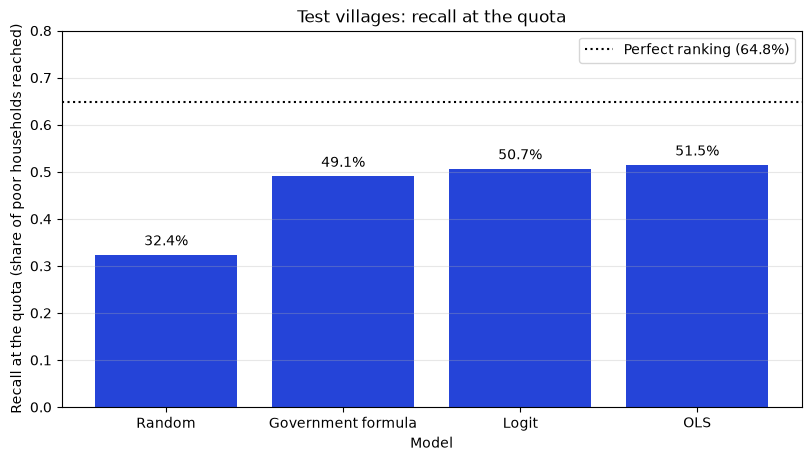

In [24]:
order = ["Random", "Government formula", "Logit", "OLS"]
values = test_results.loc[order, "recall"]

fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
ax.bar(order, values, color="#2544d8")
ax.axhline(t_perfect, color="black", linestyle=":", label=f"Perfect ranking ({t_perfect:.1%})")     # the ceiling
for i, v in enumerate(values):
    ax.text(i, v + 0.02, f"{v:.1%}", ha="center")       # value above each bar

ax.set_ylim(0, 0.8)
ax.set_xlabel("Model")
ax.set_ylabel("Recall at the quota (share of poor households reached)")
ax.set_title("Test villages: recall at the quota")
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.savefig("../outputs/figures/final_test_recall.png", dpi=200, bbox_inches="tight")
plt.show()

- **Results: OLS beats the government formula in the test villages too.** It reaches 51.5% of the poor households, against 49.1% for the government formula (+2.4 points, and for example 9 more poor households out of 375). This is the same gain as in cross-validation (+2.1 points).
- All results are lower than in cross-validation, including the random (32.4%) and the perfect ranking (64.8%). The test villages have fewer transfers per poor household (307 transfers for 375 poor, 0.82 per poor household vs. 0.89 in the training villages), so the task becomes harder for every model. As a share of the possible improvement, OLS reaches 59% while the government formula only 52%.
- Logit is really close behind, with 50.7%, as expected with the results from cross-validation. Both rank neighbours better than the government formula (within-village AUC of 0.811 for both, only 0.777 for government formula).
- The gain is small and the test only has 128 villages, so one or two villages can move the results easily by a point. But the result goes in the same direction as in 4 of the 5 cross-validation folds, so the result is consistent.

### The gain over the government formula is real gain or simply luck ?
On the test set, OLS reaches 9 more poor households than the government formula. We need to check, in two ways, if this gain could be luck: We count in how many villages OLS does better, same or worse, and we bootstrap the test villages (10,000 resamples of whole villages, because households in a village share one quota).



In [28]:
# Count, village by village, how many poor households each rule reaches
sel_ols = select_by_quota(test_eval, "OLS", higher_is_poorer=False)
sel_gov = select_by_quota(test_eval, "pcexppred", higher_is_poorer=False)
poor = test_eval["poor"] == 1

v = pd.DataFrame({"hhea": test_eval["hhea"],
                  "ols": (sel_ols == 1) & poor,
                  "gov": (sel_gov == 1) & poor,
                  "poor": poor}).groupby("hhea").sum()

print("Totals:", v[["ols", "gov", "poor"]].sum().to_dict())
print("villages: OLS more:", (v.ols > v.gov).sum(), "| fewer:", (v.ols < v.gov).sum(), "| same:", (v.ols == v.gov).sum())


# Bootstrap: draw the 128 test villages again with replacement, 10,000 times, and compute the gain each time. Whole villages are drawn, because households in a village share a quota
rng = np.random.default_rng(SEED)
gains = []
for b in range(10000):
    s = v.sample(len(v), replace=True, random_state=rng)
    gains.append((s.ols.sum() - s.gov.sum()) / s.poor.sum())
    
low, high = np.percentile(gains, [2.5, 97.5])
print(f"gain OLS - government: 95% interval {low:+.3f} to {high:+.3f}")

Totals: {'ols': 193, 'gov': 184, 'poor': 375}
villages: OLS more: 21 | fewer: 12 | same: 95
gain OLS - government: 95% interval -0.005 to +0.053


**Results:** OLS reaches more poor households in 21 villages, fewer in 12, and the same number in 95. The bootstrap 95% interval for the gain goes from -0.5% to 5.3%, including zero so the test alone cannot prove that OLS is better. The most important is thus that the direction is the same as in cross-validation (+2.1 points, OLS ahead in 4 of 5 folds).

## Conclusion

In cross-validation, the winners of the two races (OLS for consumption, Logit for poverty) were tied, so predicting directly consumption or poverty made no difference. We chose OLS before looking at the test villages because it ranks neighbours a little bit better, uses the same method as the government formula, also predicts consumption, and can thus be reused even if the poverty line or the quota changes.

In the 128 villages we used only once, OLS reaches 51.5% of the poor households against 49.1% for the government formula, so 9 more poor households out of 375. The gain does not come from a new and more complex model, but from the estimating the same kind of formula again on more recent data. The result of the test is small but consistent with cross-validation. Furthermore, it costs nothing as the government already collects the same information.